# 03 · Signatures — embryonic module geography

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Setup & paths

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

### Load · gene recovery

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 7830
Gast: 73/81 genes present
pSom: 85/98 genes present
Crest: 103/104 genes present


### GATE 2 — module geography (+ GATE 3 = NA)

In [4]:
# GATE 2 — module geography read off the signature embeddings
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho, smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_=spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
# inverse-gradient vs co-expression-hub test
pz=(adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz=(adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint=((pz>0.5)&(cz>0.5)).mean(); exp=(pz>0.5).mean()*(cz>0.5).mean()
print(f'joint pSom&Crest-high enrichment = {joint/exp:.2f} (<1 = inverse gradient, not a hub)')
# Crest-arm inversion flag: which developmental program does Crest co-locate with?
rcg=np.corrcoef(adata.obs['Crest_sm'],adata.obs['Gast_sm'])[0,1]
rcp=np.corrcoef(adata.obs['Crest_sm'],adata.obs['pSom_sm'])[0,1]
print(f'Crest vs Gast r={rcg:+.2f} | Crest vs pSom r={rcp:+.2f}',
      '-> FLAG (Crest enriches Gast end)' if rcg>rcp else '-> Crest not Gast-enriched')
print('GATE 2 = GO (non-branching): single pSom->Crest developmental axis, Crest inverse/terminal gradient')
print('GATE 3 = NA: no bifurcation (single curve, 0 forks) -> no hub to test')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.26
  Crest_sm vs Gast_sm: r = -0.75
  Crest_sm vs pSom_sm: r = -0.65
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho = -0.363
  pSom_sm: rho = -0.639
  Crest_sm: rho = +0.477
Neural-crest-high decile mean pseudotime = 0.54 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.23 (<1 = inverse gradient, not a hub)
Crest vs Gast r=-0.75 | Crest vs pSom r=-0.65 -> Crest not Gast-enriched
GATE 2 = GO (non-branching): single pSom->Crest developmental axis, Crest inverse/terminal gradient
GATE 3 = NA: no bifurcation (single curve, 0 forks) -> no hub to test


### Signature figures + colorbars

<string>:17: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:17: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:17: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


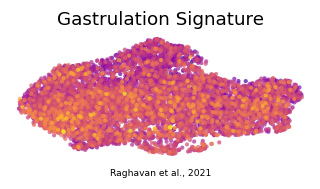

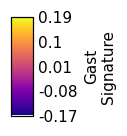

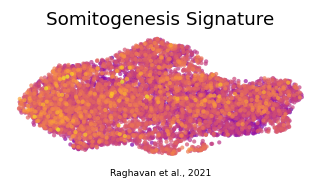

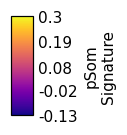

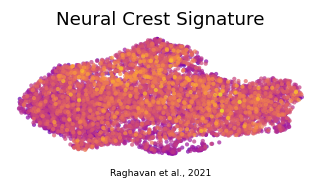

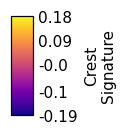

In [5]:
# signature UMAPs — RAW scores (honest deliverable), house (3.5,1.5) strip + external colorbars
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo,hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo,hi_,5),2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf + colorbar')

### Save signatures.h5ad

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7830, 16784)
